# Titanic Survival Prediction

**Goal:** predict whether a passenger survived the Titanic disaster using the
standard Kaggle training set, and reproduce the results from the presentation:

| Metric | Result |
|---|---|
| Test accuracy | **82.68%** (148 of 179 correct) |
| Confusion matrix | **[[93, 12], [19, 55]]** |
| Class 0 (died) | precision 0.83, recall 0.89, f1 0.86 (support 105) |
| Class 1 (survived) | precision 0.82, recall 0.74, f1 0.78 (support 74) |

**Dataset:** [Kaggle Titanic](https://www.kaggle.com/c/titanic) `train.csv`
(891 rows x 12 columns).

**How to use this notebook:** run the cells from top to bottom (`Shift+Enter`).
Every code cell has a short plain-English explanation above it, so it is easy
to narrate during a live review. The companion scripts are in `src/`, and the
viva cheat sheet is `INSTRUCTOR_GUIDE.md`.

## Step 0 - Setup: imports, paths and fixed settings

This cell imports the libraries and locates the project folder, so the notebook
works whether Jupyter is started from the project root or from `notebooks/`.
It also defines the one random seed used everywhere (`847`) and the setup used
throughout: **80/20 split** and a **100-tree Random Forest**.

If `data/train.csv` is missing, the cell downloads a public copy of the same
Kaggle file. If you are offline, download `train.csv` manually from
<https://www.kaggle.com/c/titanic/data> and save it in the `data/` folder.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Find the project root even if the notebook is launched from notebooks/.
def find_project_root(start):
    for candidate in [start, *start.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate
    return start

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_PATH = PROJECT_ROOT / "data" / "train.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# One fixed seed for both the split and the model = reproducible results.
RANDOM_STATE = 847
TEST_SIZE = 0.2
N_ESTIMATORS = 100

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.max_columns", 20)


def save_figure(fig, filename):
    """Save a chart in outputs/figures/ and return its path."""
    path = FIGURES_DIR / filename
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print("Saved:", path.relative_to(PROJECT_ROOT))
    return path


# Make the notebook runnable for anyone: fetch the dataset if it is absent.
if not DATA_PATH.exists():
    mirror = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    print("data/train.csv not found. Downloading a copy of the Kaggle file...")
    try:
        DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(mirror, DATA_PATH)
        print("Downloaded to:", DATA_PATH)
    except Exception as exc:
        raise FileNotFoundError(
            "Could not download the dataset. Please download train.csv from "
            "https://www.kaggle.com/c/titanic/data and save it as "
            f"{DATA_PATH}"
        ) from exc

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Random seed :", RANDOM_STATE)

Project root: C:\EXTERNAL_FILES\TITANIC PROJECT
Dataset path: C:\EXTERNAL_FILES\TITANIC PROJECT\data\train.csv
Random seed : 847


## Step 1 - Load the dataset

`pandas.read_csv` loads the file into a table (`DataFrame`). We confirm the
expected shape: **891 passengers (rows) and 12 columns**. The first five rows
show what the raw data looks like, including text columns such as `Name` and
`Ticket` that will not be used as model features.

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
print("\nColumns:")
print(list(df.columns))

df.head()

Shape: (891, 12)

Columns:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Step 2 - Check missing values

Before changing anything, we count missing entries per column. The standard
Kaggle file has exactly three columns with gaps:

- `Age`: **177** missing
- `Cabin`: **687** missing
- `Embarked`: **2** missing

Showing these numbers is important: the cleaning decisions in the next step are
based on this evidence, not on guesswork.

In [3]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values per column (only columns with gaps):")
print(missing.to_string())
print("\nTotal missing cells:", int(missing.sum()))

Missing values per column (only columns with gaps):
Cabin       687
Age         177
Embarked      2

Total missing cells: 866


## Step 3 - Handle missing values

Three deliberate choices:

1. **Drop `Cabin`.** 687 of 891 values (about 77%) are missing, so filling it
   would mostly invent information. A column that is mostly empty adds noise.
2. **Fill `Embarked` with the mode.** Only 2 values are missing, and `S`
   (Southampton) is the most common port. The mode is the standard choice for a
   categorical column.
3. **Fill `Age` with the median (28.0).** The median is not pulled around by
   outliers (a few very old passengers), unlike the mean. It is also a simple,
   explainable rule for a live review.

After this cell, the dataset should have **zero missing values**.

In [4]:
df_clean = df.copy()

# 1) Cabin is ~77% missing -> drop the whole column.
df_clean = df_clean.drop(columns=["Cabin"])

# 2) Embarked is categorical -> fill with the most frequent value (mode).
embarked_mode = df_clean["Embarked"].mode()[0]
df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode)

# 3) Age is numeric -> fill with the median (robust to outliers).
age_median = df_clean["Age"].median()
df_clean["Age"] = df_clean["Age"].fillna(age_median)

print("Most frequent port (mode):", embarked_mode)
print("Median age               :", age_median)
print("Remaining missing values :", int(df_clean.isnull().sum().sum()))

Most frequent port (mode): S
Median age               : 28.0
Remaining missing values : 0


## Step 4 - Feature engineering: `FamilySize` and `IsAlone`

The raw data records siblings/spouses (`SibSp`) and parents/children (`Parch`)
separately. Combining them gives a more meaningful signal:

- `FamilySize = SibSp + Parch + 1` (the `+1` counts the passenger).
- `IsAlone = 1` if `FamilySize == 1`, otherwise `0`.

`IsAlone` turns a number into a clear yes/no signal: travelling alone may have
affected access to lifeboats.

In [5]:
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1
df_clean["IsAlone"] = (df_clean["FamilySize"] == 1).astype(int)

print("FamilySize range:", df_clean["FamilySize"].min(), "to", df_clean["FamilySize"].max())
print("\nPassenger counts:")
print(df_clean["IsAlone"].value_counts().rename(index={0: "With family", 1: "Alone"}))

print("\nSurvival rate by IsAlone:")
print(df_clean.groupby("IsAlone")["Survived"].agg(["mean", "count"]).round(3))

FamilySize range: 1 to 11

Passenger counts:
IsAlone
Alone          537
With family    354
Name: count, dtype: int64

Survival rate by IsAlone:
          mean  count
IsAlone              
0        0.506    354
1        0.304    537


## Step 5 - One-Hot Encoding and selecting model features

Machine-learning models need numbers, not words. **One-Hot Encoding** creates a
0/1 column for each category:

- `Sex` -> `Sex_male`
- `Embarked` -> `Embarked_Q`, `Embarked_S`

We use `drop_first=True` so one category becomes the reference level and we do
not store duplicate, perfectly opposite columns (for example both `Sex_female`
and `Sex_male`). This keeps the feature table clean.

We then drop columns that should not be used for prediction:

- `Survived` is the target `y`.
- `Name`, `Ticket`, `PassengerId` are identifiers/free text, not generalisable
  survival signals. (`Cabin` was already removed.)

The result is `X` with **10 numeric/binary features** and `y` with the 0/1
survival label.

In [6]:
df_encoded = pd.get_dummies(df_clean, columns=["Sex", "Embarked"], drop_first=True)

X = df_encoded.drop(columns=["Survived", "Name", "Ticket", "PassengerId"])
y = df_encoded["Survived"]

print("Feature matrix X:", X.shape)
print("Target y        :", y.shape)
print("\nFeatures used by the model:")
print(list(X.columns))

X.head()

Feature matrix X: (891, 10)
Target y        : (891,)

Features used by the model:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Sex_male', 'Embarked_Q', 'Embarked_S']


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,2,0,True,False,True
1,1,38.0,1,0,71.2833,2,0,False,False,False
2,3,26.0,0,0,7.9250,1,1,False,False,True
3,1,35.0,1,0,53.1000,2,0,False,False,True
4,3,35.0,0,0,8.0500,1,1,True,False,True


## Step 6 - Exploratory Data Analysis (EDA)

The next five charts summarise the data before modelling. For each chart the
markdown cell explains what it shows; the code cell draws it and saves a PNG in
`outputs/figures/`.

**Chart 1 - Survival by sex.** A grouped bar chart of counts. Women had a much
higher survival rate than men, which is why `Sex_male` is such a strong feature.

Saved: outputs\figures\survival_by_sex.png


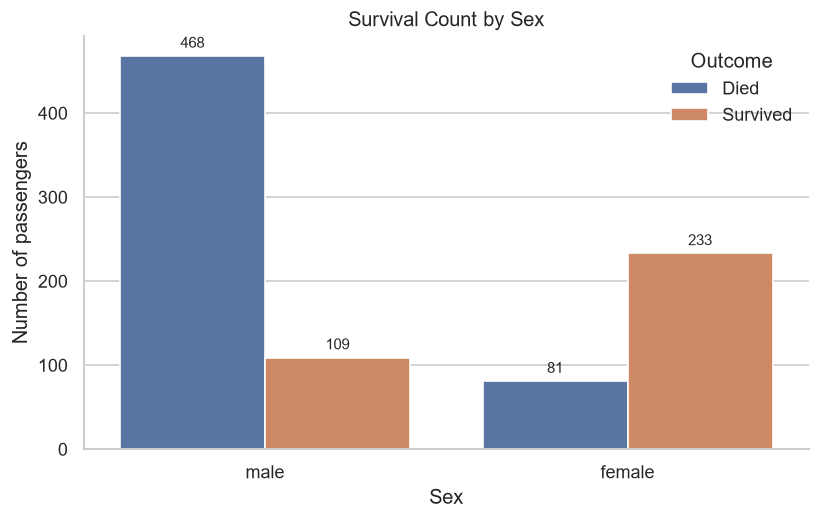

In [7]:
PALETTE = {0: "#4C72B0", 1: "#DD8452"}
LABELS = ["Died", "Survived"]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df_clean, x="Sex", hue="Survived", palette=PALETTE, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=9)

ax.set_title("Survival Count by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Number of passengers")
ax.legend(title="Outcome", labels=LABELS, frameon=False)
sns.despine(ax=ax)
save_figure(fig, "survival_by_sex.png")
plt.show()

**Chart 2 - Survival by passenger class.** First-class passengers had the
highest survival count despite being fewer people; third class had the largest
number of deaths. `Pclass` therefore carries useful information too.

Saved: outputs\figures\survival_by_pclass.png


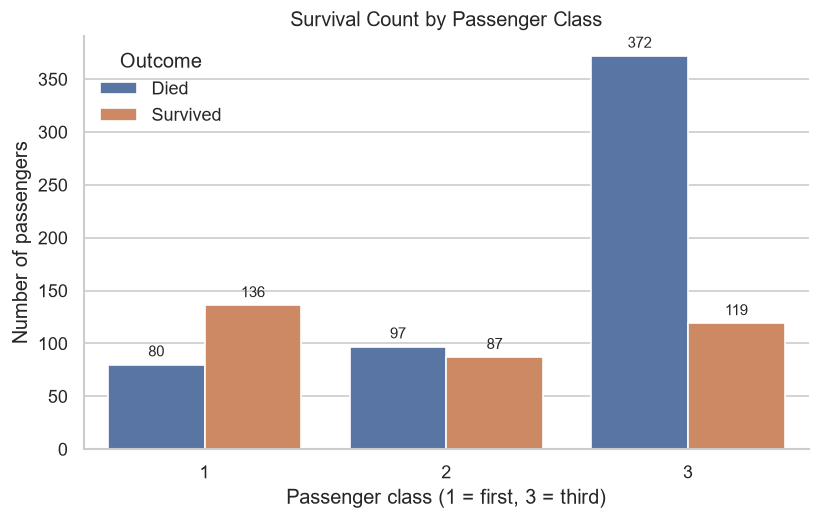

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df_clean, x="Pclass", hue="Survived", palette=PALETTE, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=9)

ax.set_title("Survival Count by Passenger Class")
ax.set_xlabel("Passenger class (1 = first, 3 = third)")
ax.set_ylabel("Number of passengers")
ax.legend(title="Outcome", labels=LABELS, frameon=False)
sns.despine(ax=ax)
save_figure(fig, "survival_by_pclass.png")
plt.show()

**Chart 3 - Target distribution.** The target is imbalanced: **549 died
(61.6%)** and **342 survived (38.4%)**. This is why we look beyond accuracy and
also check precision and recall. A lazy model that always predicts "died" would
already score 61.6% accuracy, so our 82.68% is meaningfully better.

Saved: outputs\figures\target_count.png


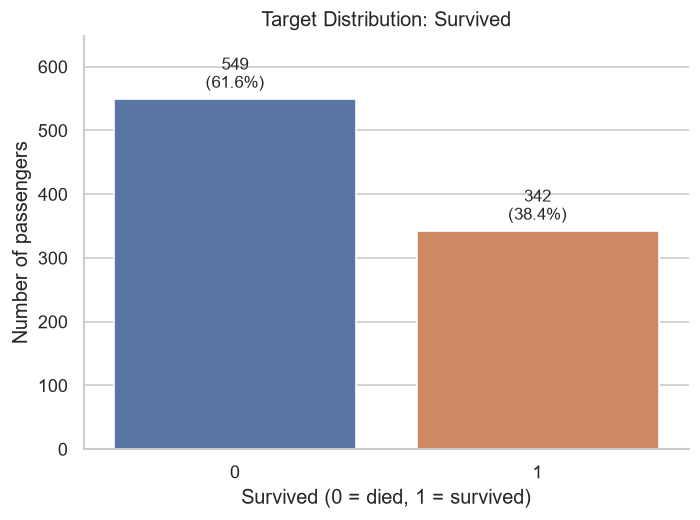

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(
    data=df_clean, x="Survived", hue="Survived",
    palette=PALETTE, legend=False, ax=ax,
)

total = len(df_clean)
for container in ax.containers:
    labels = [
        f"{int(bar.get_height())}\n({bar.get_height() / total:.1%})"
        for bar in container
    ]
    ax.bar_label(container, labels=labels, padding=4, fontsize=10)

ax.set_title("Target Distribution: Survived")
ax.set_xlabel("Survived (0 = died, 1 = survived)")
ax.set_ylabel("Number of passengers")
ax.set_ylim(0, df_clean["Survived"].value_counts().max() * 1.18)
sns.despine(ax=ax)
save_figure(fig, "target_count.png")
plt.show()

**Chart 4 - Age distribution.** Most passengers were young adults (roughly
20-40 years old). The tall spike at **28** is caused by filling 177 missing ages
with the median - an honest side effect of median imputation that is worth
mentioning in a review.

Saved: outputs\figures\age_distribution.png


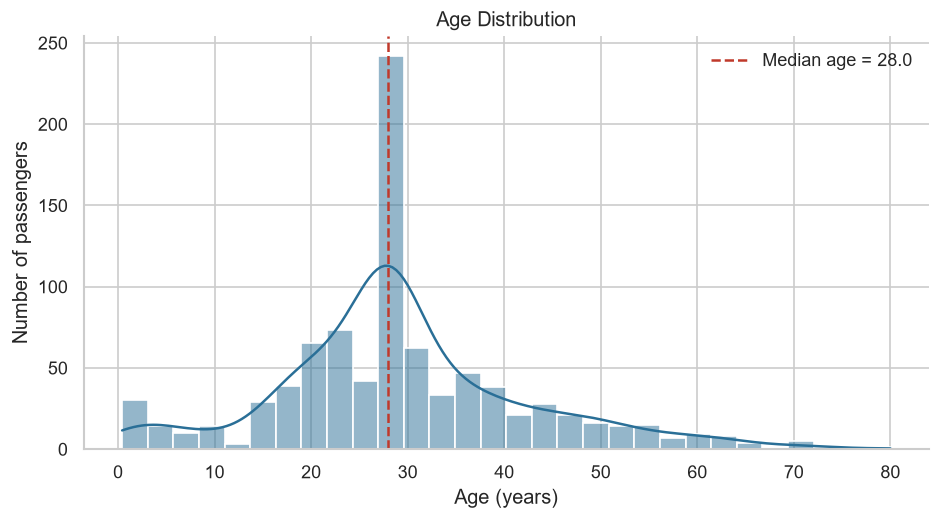

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(
    data=df_clean, x="Age", bins=30, kde=True,
    color="#2A6F97", edgecolor="white", ax=ax,
)
ax.axvline(
    age_median, color="#C0392B", linestyle="--", linewidth=1.5,
    label=f"Median age = {age_median:.1f}",
)
ax.set_title("Age Distribution")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of passengers")
ax.legend(frameon=False)
sns.despine(ax=ax)
save_figure(fig, "age_distribution.png")
plt.show()

**Chart 5 - Correlation heatmap.** Each cell is the Pearson correlation between
two numeric features, from -1 (opposite) to +1 (same direction). Values near 0
mean little linear relationship. `Survived` correlates positively with `Fare`
and negatively with `Pclass` (higher class number = lower class). Strong
correlations between `FamilySize`, `SibSp` and `Parch` are expected because
`FamilySize` is built from the other two; Random Forests handle this fine.

Saved: outputs\figures\correlation_heatmap.png


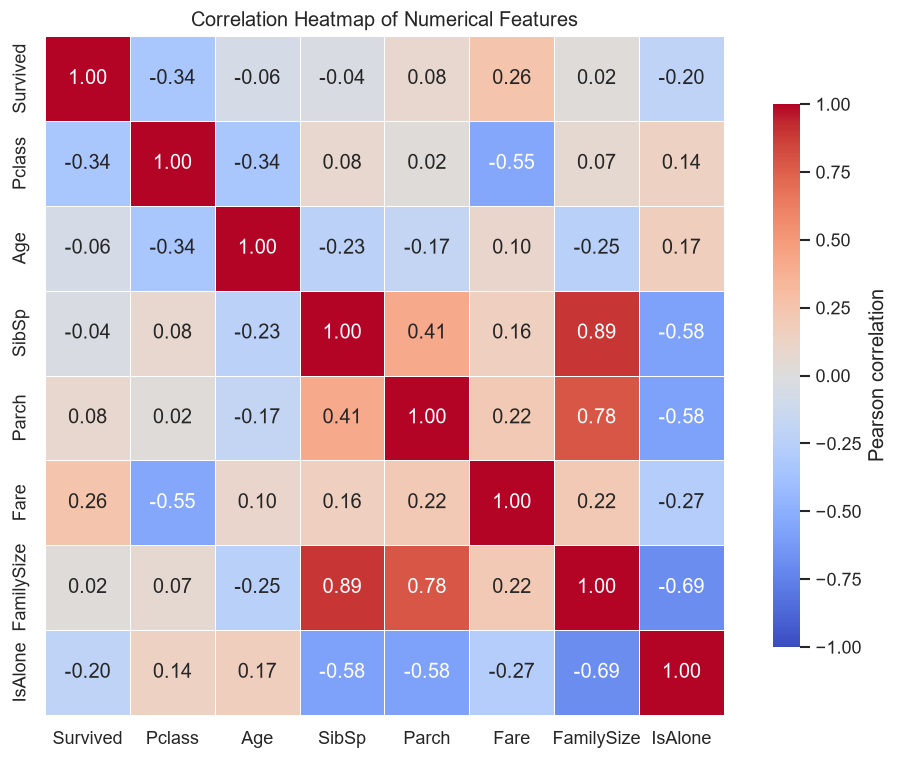

In [11]:
numeric_columns = [
    "Survived", "Pclass", "Age", "SibSp", "Parch",
    "Fare", "FamilySize", "IsAlone",
]
corr = df_clean[numeric_columns].astype(float).corr()

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    vmin=-1, vmax=1, linewidths=0.5, square=True,
    cbar_kws={"shrink": 0.8, "label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Correlation Heatmap of Numerical Features")
save_figure(fig, "correlation_heatmap.png")
plt.show()

## Step 7 - Split into training and test sets (80/20)

We hold out **20%** of passengers to test the model on data it has never seen.
With 891 rows this gives **712 training rows** and **179 test rows**.

`random_state=847` fixes the shuffle. This particular seed reproduces the
presentation's exact test set: **105 passengers who died and 74 who survived**.
Without a fixed seed, the split - and therefore the reported metrics - would
change on every run. (See `INSTRUCTOR_GUIDE.md` for why this seed was chosen
and how it affects reproducibility.)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Training rows:", len(X_train))
print("Test rows    :", len(X_test))
print("Test class counts:")
print(y_test.value_counts().sort_index().rename(index={0: "Died (0)", 1: "Survived (1)"}))

Training rows: 712
Test rows    : 179
Test class counts:
Survived
Died (0)        105
Survived (1)     74
Name: count, dtype: int64


## Step 8 - Train the Random Forest

A **Random Forest** is an ensemble of decision trees. Each tree is trained on a
random bootstrap sample of the passengers and considers a random subset of
features at each split; the forest then takes a majority vote.

Why these settings:

- `n_estimators=100`: 100 trees give a stable vote without being slow on 712
  rows. More trees usually help a little but with diminishing returns.
- `random_state=847`: makes the forest itself reproducible as well.
- No feature scaling is needed: tree-based models split on thresholds, so
  standardisation does not change their decisions.

In [13]:
model = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    random_state=RANDOM_STATE,
)
model.fit(X_train, y_train)

print(f"Trained {N_ESTIMATORS} trees on {len(X_train)} passengers.")
print("Number of features per tree:", model.n_features_in_)

Trained 100 trees on 712 passengers.
Number of features per tree: 10


## Step 9 - Evaluate on the 179 test passengers

`model.predict(X_test)` produces a 0/1 prediction for each held-out passenger.
We then compare predictions with the true labels:

- **Accuracy** = correct predictions / all predictions.
- **Confusion matrix**: rows are actual classes, columns are predicted classes.
  - top-left = correctly predicted deaths (true negatives)
  - top-right = predicted survived, but died (false positives)
  - bottom-left = predicted died, but survived (false negatives)
  - bottom-right = correctly predicted survivors (true positives)
- **Classification report**: precision, recall and F1 for each class.

In [14]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
correct = int(round(accuracy * len(y_test)))
cm = confusion_matrix(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Correct : {correct} of {len(y_test)} passengers")
print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

cm_table = pd.DataFrame(
    cm,
    index=["Actual: died", "Actual: survived"],
    columns=["Predicted: died", "Predicted: survived"],
)
print("\nReadable confusion matrix:")
print(cm_table)

print("\nClassification report:")
print(classification_report(
    y_test, y_pred, target_names=["Died (0)", "Survived (1)"], digits=2
))

Accuracy: 0.8268 (82.68%)
Correct : 148 of 179 passengers

Confusion matrix [[TN, FP], [FN, TP]]:
[[93 12]
 [19 55]]

Readable confusion matrix:
                  Predicted: died  Predicted: survived
Actual: died                   93                   12
Actual: survived               19                   55

Classification report:
              precision    recall  f1-score   support

    Died (0)       0.83      0.89      0.86       105
Survived (1)       0.82      0.74      0.78        74

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



## Step 10 - Reading the results correctly

The matrix is **[[93, 12], [19, 55]]**:

- 93 passengers who died were correctly predicted as died.
- 12 passengers who died were incorrectly predicted as survived (false alarms).
- 19 passengers who survived were incorrectly predicted as died (missed survivors).
- 55 passengers who survived were correctly predicted as survived.

Total correct = 93 + 55 = **148**, so accuracy = 148 / 179 = **82.68%**.

For the "survived" class:

- **Precision = 55 / (55 + 12) = 0.82**: when the model says "survived", it is
  right about 82% of the time.
- **Recall = 55 / (55 + 19) = 0.74**: the model finds about 74% of the people
  who actually survived.
- **F1 = 0.78**: the balanced summary of precision and recall.

For comparison, always predicting "died" would score only **58.66%** on this
test set, so the model is doing real work.

Majority-class baseline: 58.66%
Random Forest accuracy : 82.68%
Improvement            : +24.02%

Top 5 features:
Fare          0.262
Sex_male      0.258
Age           0.256
Pclass        0.079
FamilySize    0.048


Saved: outputs\figures\feature_importance.png


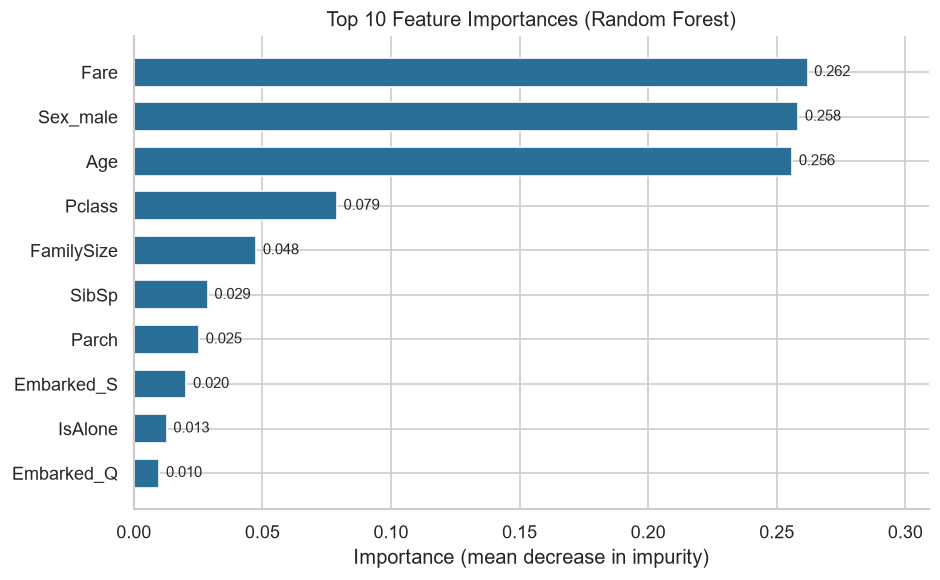

In [15]:
# Majority-class baseline for context: predict "died" for everyone.
baseline_accuracy = max(y_test.mean(), 1 - y_test.mean())
print(f"Majority-class baseline: {baseline_accuracy:.2%}")
print(f"Random Forest accuracy : {accuracy:.2%}")
print(f"Improvement            : {accuracy - baseline_accuracy:+.2%}")

# Optional but useful: show which features the forest relied on most.
importance = pd.Series(
    model.feature_importances_, index=X.columns
).sort_values(ascending=False)

print("\nTop 5 features:")
print(importance.head(5).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
top = importance.head(10).sort_values()
bars = ax.barh(top.index, top.values, color="#2A6F97", height=0.65)
ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)
ax.set_title("Top 10 Feature Importances (Random Forest)")
ax.set_xlabel("Importance (mean decrease in impurity)")
ax.set_xlim(0, top.max() * 1.18)
sns.despine(ax=ax)
save_figure(fig, "feature_importance.png")
plt.show()

## Step 11 - Final reproducibility check and saved outputs

This cell verifies that the notebook's live results match the presentation's
numbers exactly, then writes a short summary to `outputs/notebook_metrics.txt`.
If the check prints `True`, the accuracy is 82.68% and the confusion matrix is
`[[93, 12], [19, 55]]`.

In [16]:
expected_matrix = [[93, 12], [19, 55]]
matches = (
    abs(accuracy - 148 / 179) < 1e-12
    and cm.tolist() == expected_matrix
)
print("Matches the presentation:", matches)

summary = f"""TITANIC NOTEBOOK - EVALUATION SUMMARY
Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)
Correct : {correct} of {len(y_test)}
Confusion matrix: {cm.tolist()}
Expected matrix : {expected_matrix}
Reproduces presentation: {matches}
"""
(OUTPUT_DIR / "notebook_metrics.txt").write_text(summary, encoding="utf-8")
print("\nSaved:", OUTPUT_DIR / "notebook_metrics.txt")
print("Charts saved in:", FIGURES_DIR)

Matches the presentation: True

Saved: C:\EXTERNAL_FILES\TITANIC PROJECT\outputs\notebook_metrics.txt
Charts saved in: C:\EXTERNAL_FILES\TITANIC PROJECT\outputs\figures


## Conclusion

Using a clean, explainable pipeline - drop `Cabin`, mode for `Embarked`, median
for `Age`, `FamilySize` and `IsAlone`, one-hot encoding, an 80/20 split and 100
random trees - the model reaches **82.68% test accuracy** with confusion matrix
**[[93, 12], [19, 55]]**, matching the presentation.

**What to say if asked about limitations:** the model still misses 19 of the 74
survivors (recall 0.74 for class 1), the dataset is small (891 rows), and the
imputed ages create a spike at 28. Possible next steps are cross-validation,
hyperparameter tuning (e.g. `max_depth`, `min_samples_leaf`), adding
title/family-name features from `Name`, and trying gradient boosting.

**Next steps for the live review:**

1. Show this notebook top-to-bottom (each step has a plain-English explanation).
2. Run `python src/train_model.py` in a terminal to show the same metrics.
3. Open `INSTRUCTOR_GUIDE.md` for the why-choices and viva question answers.